# Murphy: LATTE through the full regional ADCP survey

Choose `SOLO_TRANSECT` below (`M1` by default). Its shallowest accepted **inner** SOLO centre supplies LATTE's initial geographic origin; a rejected SOLO Gaussian radius does not disqualify that centre. LATTE then fits **all Murphy-region ADCP observations at each measured depth**, without restricting them to either SOLO crossing or a transect time window. Each accepted LATTE inner centre seeds the next depth; rejected levels leave the previous accepted seed in place.

The overview maps the regional surface-bin ADCP vectors, both SOLO crossing tracks and their fitted surface centres. The remaining diagnostics and 2-D/3-D plots follow the SOLO notebook conventions. The survey spans 4–7 June, so spatial structure and temporal evolution can be aliased; the resulting depth profile is descriptive, not an instantaneous eddy section. “Surface” is the shallowest observed bin, 30.4 m. See [info.md](info.md) for data and crossing definitions.

In [1]:
from pathlib import Path
import importlib.util
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Rectangle

candidates = [Path.cwd(), *Path.cwd().parents,
              Path.cwd() / "seacofs_eddy_tilt_analysis" / "observations"]
OBSERVATIONS_DIR = next(p for p in candidates
                        if p.name == "observations" and (p / "esp_depth_tools.py").is_file())
spec = importlib.util.spec_from_file_location("esp_depth_tools", OBSERVATIONS_DIR / "esp_depth_tools.py")
esp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(esp)

## Controls and SOLO starting centre

Change `SOLO_TRANSECT` to `M2` to test the alternative seed. SOLO results come from `murphy_solo.ipynb`; rerun its export after changing SOLO settings. `MURPHY_BOUNDS` selects the supplied regional observations, not a crossing. The 50 km LATTE core admits two-dimensional samples around the centre; the 150 km outer limit bounds the Gaussian fit. These differ from SOLO's along-track 25 km core and are explicit method settings.

In [2]:
EDDY = "Murphy"
SOLO_TRANSECT = "M1"  # M1 or M2
STUDY_DIR = OBSERVATIONS_DIR / "MNF_IN2015_V03_adcp_trawler"
INFO_PATH = STUDY_DIR / "info.md"
BACKEND_PATH = Path("/home/z5297792/ESP_zonodo/functions.py")
DATA_PATH, transects, _ = esp.load_study(INFO_PATH, EDDY)
OUTPUT_DIR = DATA_PATH.parent / "outputs"
SOLO_RESULTS_PATH = OUTPUT_DIR / "murphy_solo_depth_fits.csv"
MURPHY_BOUNDS = (153.5, 156.0, -29.8, -27.6)  # west, east, south, north
MIN_ATTENDANCE = None

FIT = dict(core_radius=50_000., outer_radius=120_000.,
           max_centre_step=200_000., radius_limit=150_000.,
           min_core_points=1, min_outer_points=1,
           expected_sign=-1, require_peak_bracket=True)
MAP_DEPTHS = (30, 100, 200, 300, 400, 500, 600, 700)
HALF_WIDTH_KM = 100
VELOCITY_LIMIT = 1

if SOLO_TRANSECT not in transects.index:
    raise ValueError(f"SOLO_TRANSECT must be one of {list(transects.index)}")
solo = pd.read_csv(SOLO_RESULTS_PATH)
required = {"transect_id", "depth_m", "inner_valid", "xc_lon", "yc_lat"}
if not required.issubset(solo.columns):
    raise ValueError(f"Missing SOLO output columns: {required - set(solo.columns)}")
solo["inner_valid"] = solo.inner_valid.astype(str).str.lower().eq("true")
selected = solo.loc[solo.transect_id.eq(SOLO_TRANSECT) & solo.inner_valid].sort_values("depth_m")
if selected.empty:
    raise ValueError(f"No accepted SOLO inner centre for {SOLO_TRANSECT}")
SOLO_REF = selected.iloc[0]
ORIGIN_LON_LAT = (float(SOLO_REF.xc_lon), float(SOLO_REF.yc_lat))
print(f"LATTE initial centre: {SOLO_TRANSECT} SOLO inner fit at {SOLO_REF.depth_m:g} m, "
      f"({ORIGIN_LON_LAT[0]:.5f}°E, {ORIGIN_LON_LAT[1]:.5f}°N); "
      f"Gaussian status: {SOLO_REF.status}")

LATTE initial centre: M1 SOLO inner fit at 30.4 m, (154.85023°E, -28.61157°N); Gaussian status: peak_not_bracketed


## Surface ADCP overview

Grey arrows sample the full Murphy-region survey at the shallowest ADCP bin. Coloured lines show the two short SOLO crossings; crosses mark their shallowest accepted inner centres. The red frame is the regional selection. The vectors were sampled over several days.

selected_rows                                             39422
used_rows                                                 39422
unique_times                                                876
start_utc                             2015-06-04 00:01:22+00:00
end_utc                               2015-06-07 01:56:23+00:00
depth_range_m                                     [30.4, 814.4]
missing_avg_qc                                            39422
zero_attendance_rows                                      19420
min_attendance                                             None
origin_lon_lat          (154.8502273180815, -28.61156558011225)
bounds_lon_lat                     (153.5, 156.0, -29.8, -27.6)
Name: LATTE selection audit, dtype: object

path                 /home/z5297792/ESP_zonodo/functions.py
sha256    8e4b06fe4c144f7a70671ee913b6d27784f9cdb587e9b0...
Name: ESP backend, dtype: object

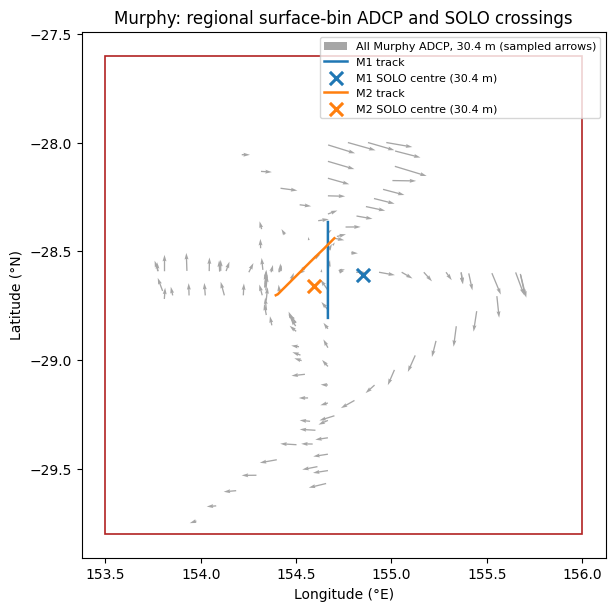

In [3]:
backend, backend_info = esp.load_backend(BACKEND_PATH)
data, coverage, audit = esp.load_observations(
    DATA_PATH, None, None, ORIGIN_LON_LAT,
    min_attendance=MIN_ATTENDANCE, bounds=MURPHY_BOUNDS)
display(pd.Series(audit, name="LATTE selection audit"))
display(pd.Series(backend_info, name="ESP backend"))

surface = data.loc[data.depth.eq(data.depth.min())].sort_values("time")
fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)
shown = surface.iloc[::max(1, len(surface)//120)]
ax.quiver(shown.lon, shown.lat, shown.u, shown.v, color="0.65", width=.0025,
          scale=17, label=f"All Murphy ADCP, {surface.depth.min():g} m (sampled arrows)")
for colour, (ident, crossing) in zip(("tab:blue", "tab:orange"), transects.iterrows()):
    track = surface.loc[surface.time.between(pd.Timestamp(crossing.start), pd.Timestamp(crossing.end))]
    ax.plot(track.lon, track.lat, color=colour, lw=1.8, label=f"{ident} track")
    fitted = solo.loc[solo.transect_id.eq(ident) & solo.inner_valid].sort_values("depth_m")
    if not fitted.empty:
        first = fitted.iloc[0]
        ax.scatter(first.xc_lon, first.yc_lat, marker="x", s=90, lw=2.2,
                   color=colour, zorder=5, label=f"{ident} SOLO centre ({first.depth_m:g} m)")
ax.add_patch(Rectangle((MURPHY_BOUNDS[0], MURPHY_BOUNDS[2]),
                       MURPHY_BOUNDS[1]-MURPHY_BOUNDS[0],
                       MURPHY_BOUNDS[3]-MURPHY_BOUNDS[2],
                       fill=False, edgecolor="firebrick", lw=1.2))
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)",
       title="Murphy: regional surface-bin ADCP and SOLO crossings")
ax.set_aspect(1/np.cos(np.deg2rad(surface.lat.mean())))
ax.legend(fontsize=8, loc="best")
plt.show()

## LATTE fits from shallow to deep

Every depth uses the full regional sample at that depth. Accepted inner fits update the centre and ellipse used to select the next core, even if the Gaussian outer stage fails. The table retains failed levels and separates centre support from reconstruction support.

LATTE: 48/50 accepted inner fits; 48/50 accepted Gaussian reconstructions.
status
collinear_latte_sampling     1
invalid_ellipse              1
ok                          48
Centre offsets reference the shallowest accepted fit: 30.4 m.
Reconstructed measured levels: 30.4–798.4 m (gaps retained).
The ADCP sampling limit is not an estimate of the eddy bottom. R² is in-sample.


,depth_m,status,n_obs,n_core,inner_valid,valid,core_spread_ratio,inner_R2,alpha,Rc_m,vector_R2
0,30.4,ok,875,425,True,True,0.8410,0.7415,1.1542,123576.0158,0.7700
1,46.4,ok,861,444,True,True,0.8491,0.7201,1.1321,130274.7080,0.7877
2,62.4,ok,848,441,True,True,0.8437,0.7490,1.1026,135008.3485,0.8065
3,78.4,ok,842,440,True,True,0.8418,0.7205,1.1122,141554.1418,0.8121
4,94.4,ok,841,442,True,True,0.8270,0.6844,1.1345,140472.2175,0.8023
5,110.4,ok,839,443,True,True,0.7949,0.6620,1.1470,140578.6545,0.7979
6,126.4,ok,838,449,True,True,0.7636,0.6747,1.2160,130337.1835,0.7924
7,142.4,ok,835,446,True,True,0.7594,0.6891,1.2290,127722.1046,0.7921
8,158.4,ok,833,445,True,True,0.7467,0.6912,1.2314,126498.1644,0.7940
9,174.4,ok,832,446,True,True,0.7334,0.6975,1.2395,124573.6454,0.7969


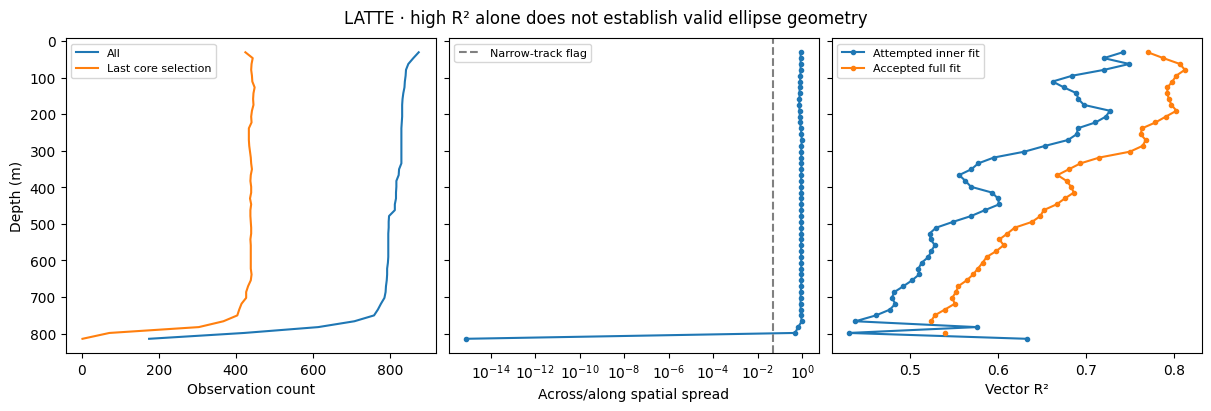

In [4]:
results, samples = esp.fit_depths(
    data, backend, "LATTE", depth_levels=coverage.index, **FIT)
esp.report(results)
columns = ["depth_m", "status", "n_obs", "n_core", "inner_valid", "valid",
           "core_spread_ratio", "inner_R2", "alpha", "Rc_m", "vector_R2"]
with pd.option_context("display.max_rows", 60):
    display(results[columns].round(4))
esp.plot_diagnostics(results)
plt.show()

## Centre trajectory and reconstruction

Offsets are relative to LATTE's shallowest accepted centre; the chosen SOLO centre is only its initial seed. The horizontal maps, 3-D view and fixed zonal/meridional sections use the same helper and scales as the SOLO notebook. Reconstructed flow away from sampled points is model-based extrapolation, and the deepest ADCP bin does not define the eddy bottom.

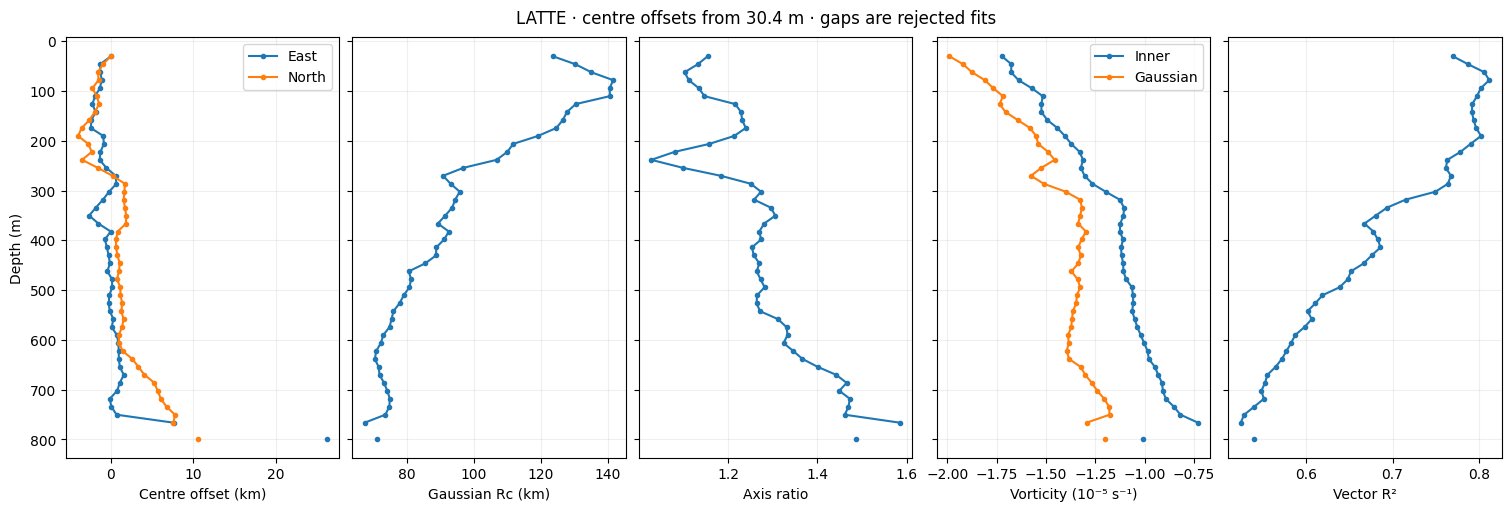

In [5]:
esp.plot_profiles(results)
plt.show()

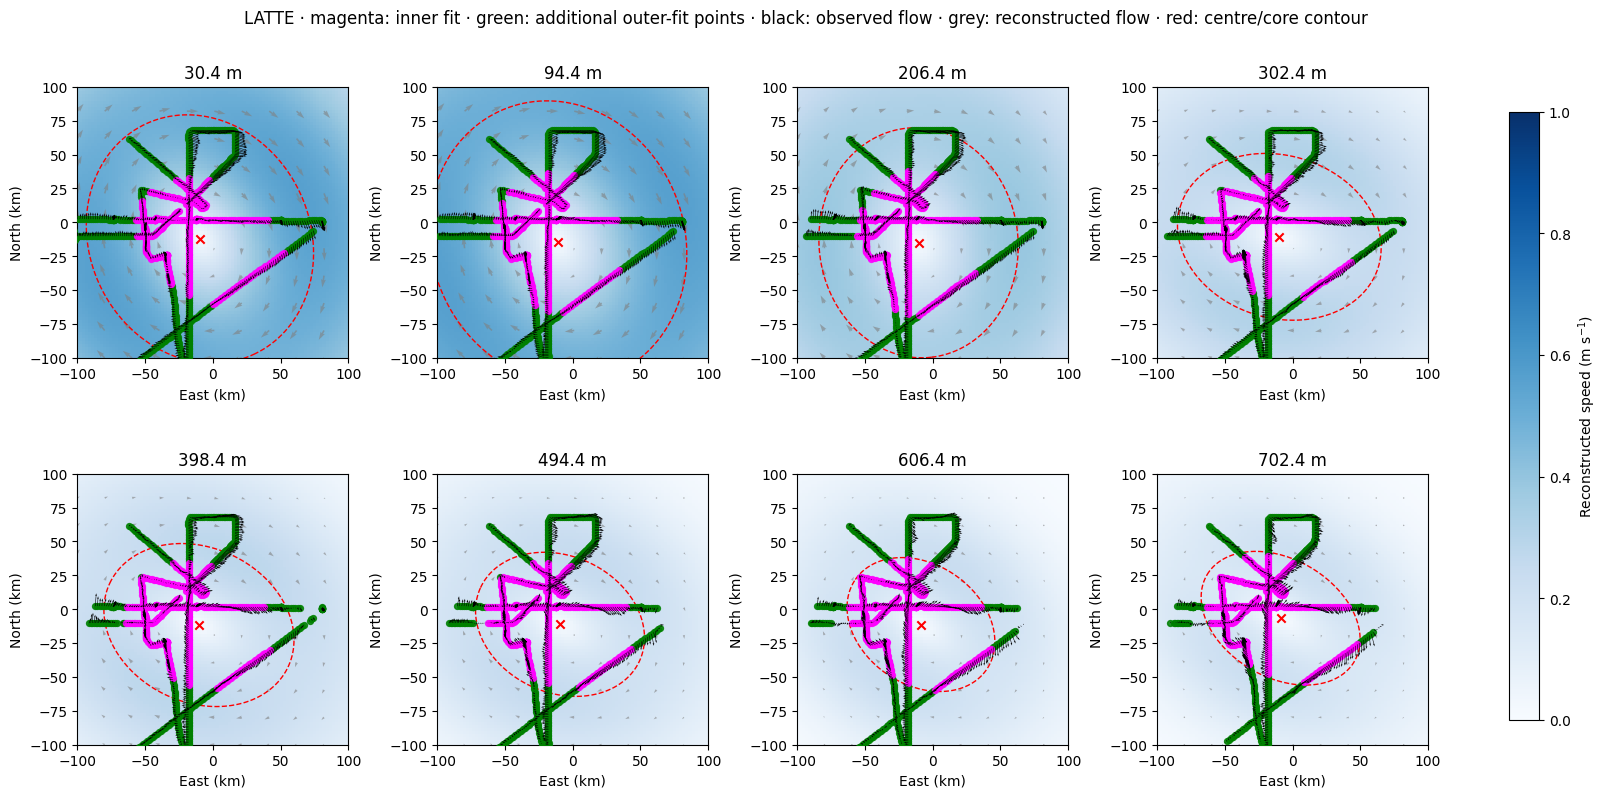

In [6]:
esp.plot_maps(results, samples, backend, depths=MAP_DEPTHS,
              half_width_km=HALF_WIDTH_KM, speed_max=VELOCITY_LIMIT)
plt.show()

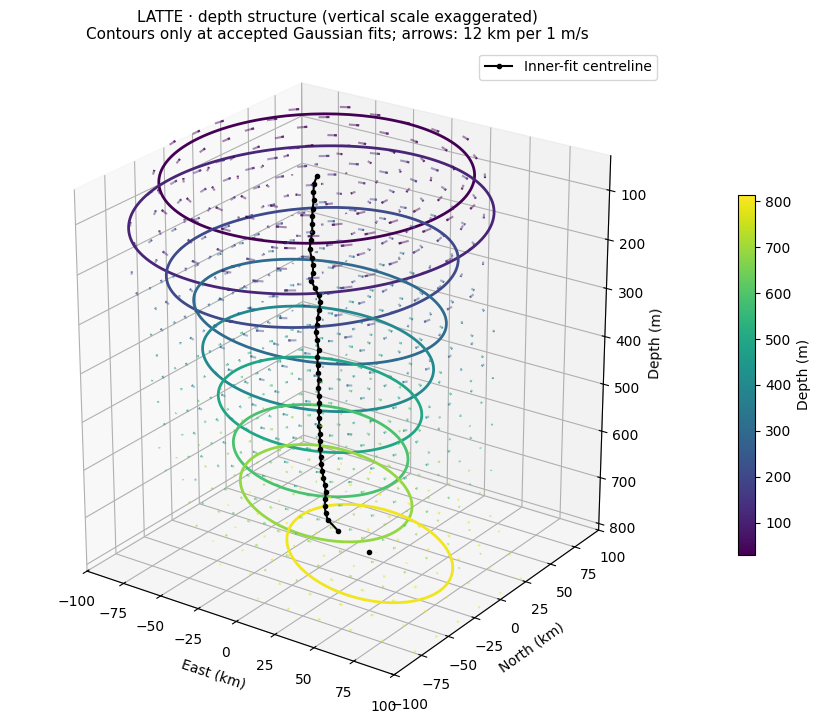

In [7]:
esp.plot_3d(results, backend, half_width_km=HALF_WIDTH_KM)
plt.show()

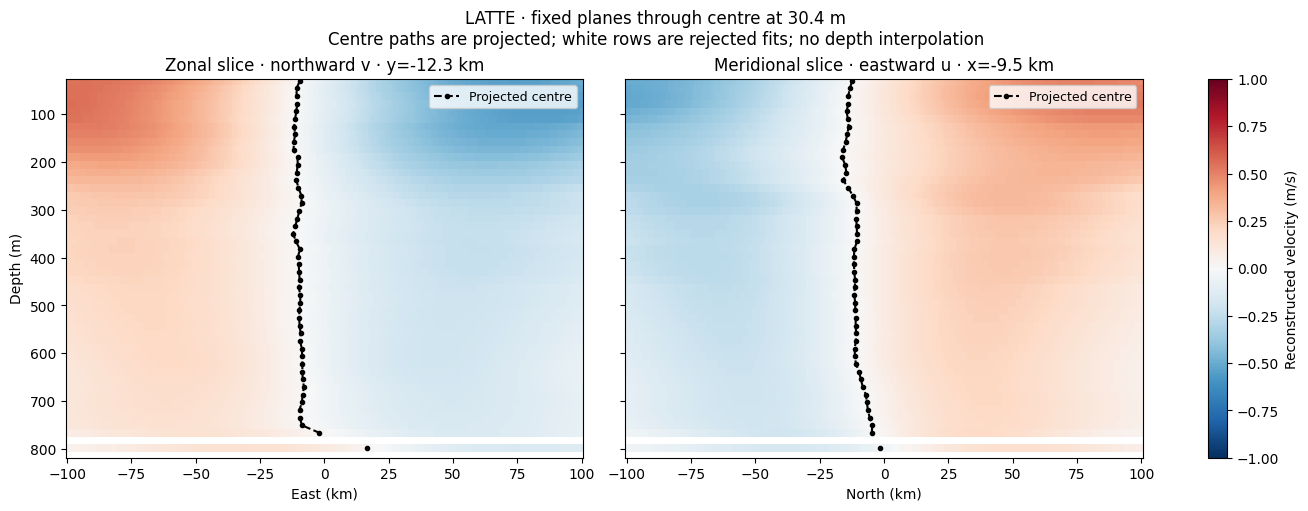

In [8]:
esp.plot_sections(results, backend, half_width_km=HALF_WIDTH_KM,
                  speed_max=VELOCITY_LIMIT)
plt.show()

## Export to scratch

The CSV includes accepted and rejected depths. The companion JSON records the full regional selection, SOLO seed, fit settings and backend fingerprint. Both stay beside this voyage's input CSV under `outputs/`.

In [9]:
SAVE_RESULTS = True
if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    results.to_csv(OUTPUT_DIR / "murphy_latte_depth_fits.csv", index=False)
    provenance = dict(eddy=EDDY, method="LATTE", data_path=str(DATA_PATH),
                      info_path=str(INFO_PATH), backend=backend_info,
                      solo_results_path=str(SOLO_RESULTS_PATH),
                      solo_transect=SOLO_TRANSECT,
                      solo_surface_fit=SOLO_REF.to_dict(),
                      selection=audit, fit_settings=FIT)
    (OUTPUT_DIR / "murphy_latte_provenance.json").write_text(
        json.dumps(provenance, indent=2, default=str))
    print(f"Saved LATTE results to {OUTPUT_DIR}")

Saved LATTE results to /srv/scratch/z5297792/tilt_observation_data/MNF_IN2015_V03_adcp_trawler/outputs
